# Notebook 02B — SMAP quality and spatial-coverage diagnostics

**CHT Forest Ecohydrology and Machine Learning** — Rangamati, Bandarban and Khagrachhari.

Notebook 02 found that only ~8.45% (January 2020) and ~3.63% (July 2020) of the region's *sampled* coarse-grid area was QA-valid on an average day. Here we check **why**: image-band availability versus the quality filter, AM versus PM, and the geographic distribution of QA-valid observations over 2017–2022.

**Scope:** read-only queries to Earth Engine; optional small CSV/PNG files saved on your PC. No image exports, training, credentials in code, shapefile edits, or GitHub changes. Run after Notebooks 00, 01 and 02.

## 1. Load study configuration and initialize Earth Engine

Earth Engine must be initialized **before** constructing `ee.Geometry` objects. We use the same in-memory simplified boundary as Notebook 02 so the pilot is comparable; original district boundaries remain untouched.

In [1]:
from pathlib import Path
import json
import ee
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import mapping
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p / 'configs' / 'study_config.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Launch JupyterLab from the project root or notebooks folder.')
CONFIG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
ee.Initialize(project=CONFIG['gee_project_id'])  # INITIALIZE FIRST
districts = gpd.read_file(ROOT / CONFIG['boundary_relative_path'])
assert districts.crs is not None and districts.geometry.is_valid.all()
NAME = CONFIG['district_name_field']
assert set(districts[NAME]) == set(CONFIG['expected_districts'])
districts_wgs84 = districts.to_crs('EPSG:4326')
union = districts_wgs84.geometry.union_all().simplify(0.001, preserve_topology=True)
AOI = ee.Geometry(mapping(union))
START, END = CONFIG['study_start'], CONFIG['study_end_exclusive']
assert START == '2017-01-01' and END == '2023-01-01', (
    'This version was designed for 2017–2022 SMAP v005. Review before changing the period.'
)
SMAP = ee.ImageCollection(CONFIG['smap_collection_for_period'])
assert CONFIG['smap_collection_for_period'] == 'NASA/SMAP/SPL3SMP_E/005'
N_CALENDAR_DAYS = (pd.Timestamp(END) - pd.Timestamp(START)).days
N_IMAGES = SMAP.filterDate(START, END).filterBounds(AOI).size().getInfo()
REFERENCE_PROJ = ee.Image(SMAP.first()).select('soil_moisture_am').projection()
SAVE_RESULTS = True  # Only local outputs/tables, outputs/figures and outputs/maps
print('Cloud project:', CONFIG['gee_project_id'])
print('Period:', START, 'to', END, '(exclusive)')
print('Calendar days:', N_CALENDAR_DAYS, 'SMAP images:', N_IMAGES)
print('Districts:', ', '.join(sorted(districts_wgs84[NAME])))

Cloud project: axial-paratext-491911-b6
Period: 2017-01-01 to 2023-01-01 (exclusive)
Calendar days: 2191 SMAP images: 2110
Districts: Bandarban, Khagrachhari, Rangamati


## 2. Define consistent image-availability and quality masks

The Google Earth Engine ingestion pipeline converts the original SMAP retrieval quality bit flags into a pass/fail layer. Thus `retrieval_qual_flag_* == 0` is the recommended-quality condition **for this GEE collection**. A band being non-missing (`*_raw`) does **not** imply recommended quality (`*_qa`).

- `am_raw` and `pm_raw`: soil-moisture band present (and in the physical range [0, 1]).
- `am_qa` and `pm_qa`: band present, plausible value, and QA flag `0`.
- `either_qa`: a *diagnostic* union of AM and PM availability; **not** a merged soil-moisture measurement.

Source documentation: [SMAP GEE catalog](https://developers.google.com/earth-engine/datasets/catalog/NASA_SMAP_SPL3SMP_E_005), [Google catalog preprocessing](https://github.com/google/earthengine-catalog/blob/main/pipelines/smap_convert_l3.py), [NSIDC QA interpretation](https://nsidc.org/data/user-resources/help-center/how-do-i-interpret-surface-and-quality-flag-information-level-2-and-3-passive-soil-moisture-products).

In [2]:
EXPECTED_BANDS = {'soil_moisture_am', 'soil_moisture_pm',
                  'retrieval_qual_flag_am', 'retrieval_qual_flag_pm'}
available_bands = set(ee.Image(SMAP.first()).bandNames().getInfo())
assert EXPECTED_BANDS.issubset(available_bands), 'A required SMAP band is unavailable.'

def quality_indicators(image):
    image = ee.Image(image)
    result = []
    for period in ('am', 'pm'):
        soil = image.select('soil_moisture_' + period)
        flag = image.select('retrieval_qual_flag_' + period)
        physical = soil.gte(0).And(soil.lte(1))
        # Starting from soil retains SMAP's projection and existing data mask.
        one = soil.multiply(0).add(1)
        raw = one.updateMask(physical).unmask(0).rename(period + '_raw')
        good = one.updateMask(physical.And(flag.eq(0))).unmask(0).rename(period + '_qa')
        result.extend([raw, good])
    either = result[1].Or(result[3]).rename('either_qa')
    return ee.Image.cat(result + [either]).toFloat()

INDICATORS = ['am_raw', 'am_qa', 'pm_raw', 'pm_qa', 'either_qa']
print('Required bands are available. Indicator bands:', INDICATORS)

Required bands are available. Indicator bands: ['am_raw', 'am_qa', 'pm_raw', 'pm_qa', 'either_qa']


## 3. January/July 2020: daily AM versus PM diagnostics

The calculation uses the same two pilot months as Notebook 02. Each value is the fraction of the **sampled coarse grid** satisfying the indicated condition, not the percent of independently measured forest area. Days without a SMAP image are retained as missing (`NaN`), not zero. Earth Engine may take time to evaluate approximately 62 daily reductions.

In [3]:
MONTHS = [('2020-01-01', '2020-02-01'), ('2020-07-01', '2020-08-01')]

def one_day_feature(item):
    image = ee.Image(item)
    stats = quality_indicators(image).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=AOI,
        crs=REFERENCE_PROJ, scale=9000, maxPixels=1000000, tileScale=2)
    return ee.Feature(None, stats).set('date', image.date().format('YYYY-MM-dd'))

frames = []
for first, last in MONTHS:
    subset = SMAP.filterDate(first, last).filterBounds(AOI).sort('system:time_start')
    count = subset.size().getInfo()
    print('Processing', first[:7], 'with', count, 'images')
    if count:
        records = ee.FeatureCollection(subset.toList(count).map(one_day_feature)).getInfo()['features']
        observed = pd.DataFrame([f['properties'] for f in records])
        observed['date'] = pd.to_datetime(observed['date'])
        observed = observed.groupby('date', as_index=False)[INDICATORS].mean()
    else:
        observed = pd.DataFrame({'date': pd.Series(dtype='datetime64[ns]'),
                                 **{x: pd.Series(dtype='float64') for x in INDICATORS}})
    calendar = pd.DataFrame({'date': pd.date_range(first, pd.Timestamp(last) - pd.Timedelta(days=1))})
    frame = calendar.merge(observed, on='date', how='left')
    frame['month'] = first[:7]
    frame['has_image'] = frame['date'].isin(observed['date'])
    frames.append(frame)
daily = pd.concat(frames, ignore_index=True)
display(daily.head())

Processing 2020-01 with 31 images
Processing 2020-07 with 31 images


,date,am_raw,am_qa,pm_raw,pm_qa,either_qa,month,has_image
0,2020-01-01,0.919252,0.153935,0.000000,0.000000,0.153935,2020-01,True
1,2020-01-02,0.931192,0.153183,0.980299,0.159153,0.159573,2020-01,True
2,2020-01-03,0.000000,0.000000,0.000000,0.000000,0.000000,2020-01,True
3,2020-01-04,0.954695,0.124638,0.177991,0.000000,0.124638,2020-01,True
4,2020-01-05,0.994362,0.160922,0.959913,0.143321,0.170849,2020-01,True


,month,calendar_days,days_with_image,days_with_any_am_qa,days_with_any_pm_qa,mean_am_raw_pct,mean_am_qa_pct,mean_pm_raw_pct,mean_pm_qa_pct,mean_either_qa_pct
0,2020-01,31,31,16,11,49.35,8.45,38.04,5.79,10.72
1,2020-07,31,31,15,10,51.00,3.63,38.76,1.30,4.27


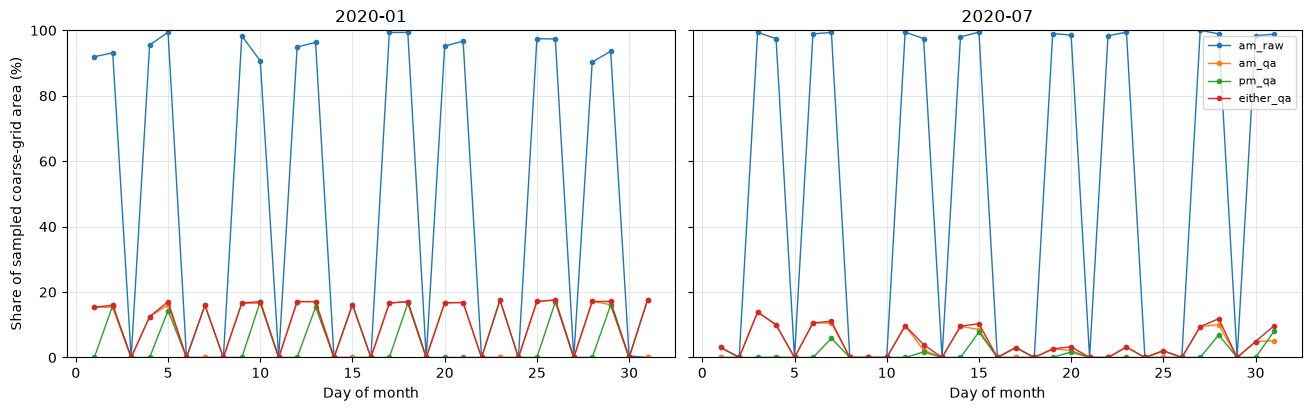

In [4]:
summary_rows = []
for month, frame in daily.groupby('month', sort=True):
    row = {'month': month, 'calendar_days': len(frame),
           'days_with_image': int(frame['has_image'].sum()),
           'days_with_any_am_qa': int((frame['am_qa'] > 0).sum()),
           'days_with_any_pm_qa': int((frame['pm_qa'] > 0).sum())}
    for band in INDICATORS:
        row['mean_' + band + '_pct'] = round(frame[band].mean() * 100, 2)
    summary_rows.append(row)
month_summary = pd.DataFrame(summary_rows)
display(month_summary)

fig1, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True, constrained_layout=True)
for ax, (month, frame) in zip(axes, daily.groupby('month', sort=True)):
    x = frame['date'].dt.day
    for label in ('am_raw', 'am_qa', 'pm_qa', 'either_qa'):
        ax.plot(x, 100 * frame[label], marker='.', linewidth=1, label=label)
    ax.set(title=month, xlabel='Day of month', ylim=(0, 100))
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Share of sampled coarse-grid area (%)')
axes[1].legend(loc='upper right', fontsize=8)
plt.show()

## 4. Full-period per-grid counts (2017–2022)

**This is the main diagnostic and may take longer** because Earth Engine must sum indicators for every SMAP daily image in six years. It samples only coarse SMAP-grid locations inside the study area; it does **not** export full rasters.

At each grid sample, `am_qa` and `pm_qa` become the **number of images with quality-passing soil moisture** during the full window. `either_qa` counts days with at least one good AM or PM retrieval (provided the daily collection has one image per day). Divide by all calendar days to include sensor outages in the denominator. The sampled locations are not independent 9 km footprint measurements.

**Note:** This exploratory map labels each *sample point* by the count in the surrounding coarse pixel. It should not be published as a higher-resolution continuous soil-moisture map.

In [5]:
full_period = SMAP.filterDate(START, END).filterBounds(AOI)
valid_count_image = full_period.map(quality_indicators).select(
    ['am_qa', 'pm_qa', 'either_qa']).sum()
sample_features = valid_count_image.sample(
    region=AOI, projection=REFERENCE_PROJ, scale=9000,
    geometries=True, tileScale=2).getInfo()['features']
if not sample_features:
    raise RuntimeError('No grid samples returned. Check SMAP coverage and AOI.')
grid_rows = []
for f in sample_features:
    coords = f['geometry']['coordinates']
    grid_rows.append({'longitude': coords[0], 'latitude': coords[1],
                      **{name: f['properties'].get(name) for name in
                         ('am_qa', 'pm_qa', 'either_qa')}})
grid = pd.DataFrame(grid_rows)
for name in ('am_qa', 'pm_qa', 'either_qa'):
    grid[name + '_pct_calendar_days'] = 100 * grid[name] / N_CALENDAR_DAYS
display(grid.head())
print('Number of coarse-grid sample locations:', len(grid))

,longitude,latitude,am_qa,pm_qa,either_qa,am_qa_pct_calendar_days,pm_qa_pct_calendar_days,either_qa_pct_calendar_days
0,92.256905,23.721009,0,0,0,0.0,0.0,0.0
1,92.014360,23.640161,0,0,0,0.0,0.0,0.0
2,92.095208,23.640161,0,0,0,0.0,0.0,0.0
3,92.176056,23.640161,0,0,0,0.0,0.0,0.0
4,92.256905,23.640161,0,0,0,0.0,0.0,0.0


Number of coarse-grid sample locations: 179


## 5. District comparison and sampled-grid map

District results are averages of sample points whose centers fall within each polygon (not area-weighted estimates). The original three-feature shapefile stays unchanged.

,adm2_name,sampled_cells,mean_am_valid_days,mean_pm_valid_days,mean_either_valid_days,mean_am_pct_calendar_days,mean_pm_pct_calendar_days,mean_either_pct_calendar_days
0,Bandarban,63,105.75,75.14,144.10,4.83,3.43,6.58
1,Khagrachhari,39,430.46,302.59,573.44,19.65,13.81,26.17
2,Rangamati,77,11.66,8.78,15.90,0.53,0.40,0.73


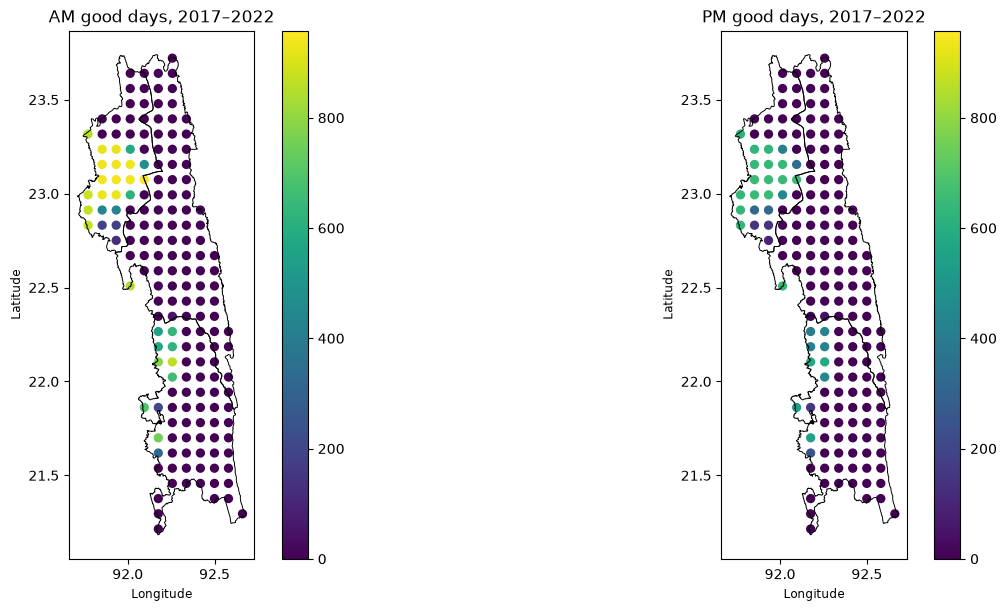

In [6]:
points = gpd.GeoDataFrame(
    grid.copy(), geometry=gpd.points_from_xy(grid['longitude'], grid['latitude']), crs='EPSG:4326')
tagged = gpd.sjoin(points, districts_wgs84[[NAME, 'geometry']], how='inner', predicate='within')
district_summary = tagged.groupby(NAME).agg(
    sampled_cells=('am_qa', 'size'),
    mean_am_valid_days=('am_qa', 'mean'),
    mean_pm_valid_days=('pm_qa', 'mean'),
    mean_either_valid_days=('either_qa', 'mean')
).reset_index()
for variant in ('am', 'pm', 'either'):
    district_summary['mean_' + variant + '_pct_calendar_days'] = (
        district_summary['mean_' + variant + '_valid_days'] / N_CALENDAR_DAYS * 100).round(2)
display(district_summary.round(2))

fig2, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
common_max = max(1, grid[['am_qa', 'pm_qa']].max().max())
for ax, variant, title in zip(axes, ('am_qa', 'pm_qa'), ('AM good days', 'PM good days')):
    districts_wgs84.boundary.plot(ax=ax, color='black', linewidth=0.7)
    points.plot(ax=ax, column=variant, cmap='viridis', markersize=32,
                legend=True, vmin=0, vmax=common_max)
    ax.set(title=title + ', 2017–2022', xlabel='Longitude', ylabel='Latitude')
plt.show()

## 6. Save diagnostic files and stop for interpretation

By default the following cell saves **four small CSV tables and two PNG figures locally**. No Earth Engine export tasks, model files or repository commits are created. You can set `SAVE_RESULTS = False` in Cell 2 to prevent file writing.

In [7]:
if SAVE_RESULTS:
    tables = ROOT / 'outputs' / 'tables'
    figures = ROOT / 'outputs' / 'figures'
    maps = ROOT / 'outputs' / 'maps'
    for folder in (tables, figures, maps):
        folder.mkdir(parents=True, exist_ok=True)
    daily.to_csv(tables / '02B_daily_quality_comparison.csv', index=False)
    month_summary.to_csv(tables / '02B_month_quality_summary.csv', index=False)
    grid.to_csv(tables / '02B_grid_observation_days.csv', index=False)
    district_summary.to_csv(tables / '02B_district_observation_days.csv', index=False)
    fig1.savefig(figures / '02B_am_pm_pilot_coverage.png', dpi=180, bbox_inches='tight')
    fig2.savefig(maps / '02B_smap_grid_valid_days.png', dpi=180, bbox_inches='tight')
    print('Saved four CSV files, one figure and one map in outputs/.')
else:
    print('SAVE_RESULTS=False; no files written.')

Saved four CSV files, one figure and one map in outputs/.


## Decision gate before Notebook 03

Please share the **four 02B CSV files** and, if possible, the **grid-coverage map**. We will answer:

1. Is the weak January/July coverage caused mainly by missing band data, failed QA, or both?
2. Does PM contribute substantially different valid-observation availability from AM?
3. Are any of the three districts and their coarse-grid sample cells sufficiently observed for model development and *withheld-observation testing*?
4. Should the project focus on a subset of grid cells, or must the research question be reframed as a data-availability/feasibility study?

**Critical limitations:** The QA counts are not field validation, not a 9 km independent ground measurement, and not evidence that forest-specific SMAP accuracy is high. Do not merge AM and PM soil-moisture values automatically, infer slope/forest causes without separate evidence, or train a model where there is no trustworthy target to test against.